- In todays lecture we will see how backpropogation is used in both regression and classification

- We will not use keras, we will implement the logic of backpropogation ourselves that we learned in the previous lecture

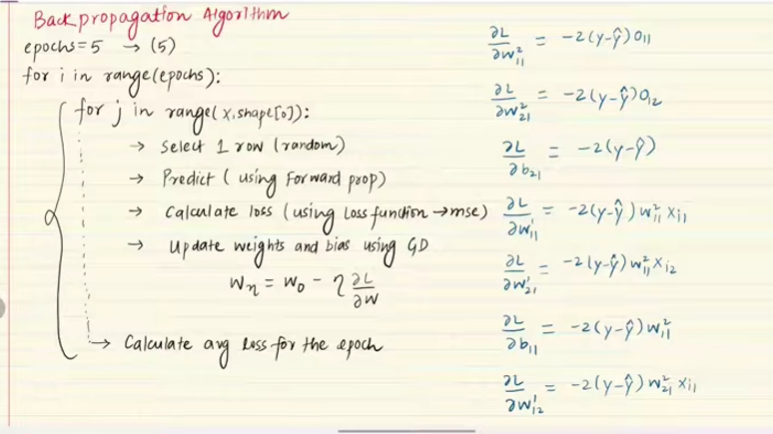

# Regression

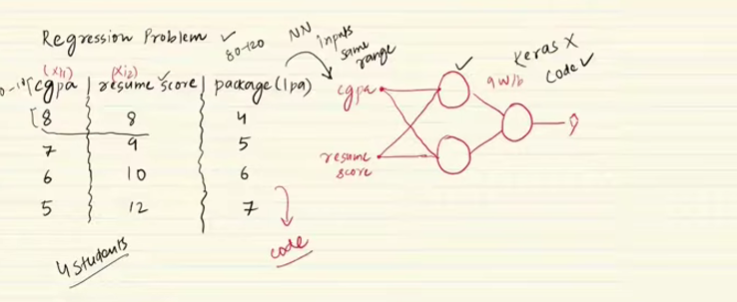
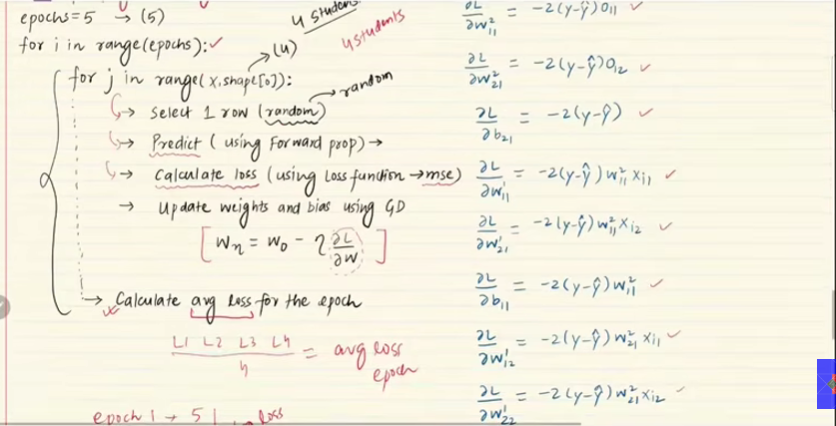

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.DataFrame([[8,8,4],[7,9,5],[6,10,6],[5,12,7]], columns=['cgpa', 'profile_score', 'lpa'])

In [3]:
df

,cgpa,profile_score,lpa
0,8,8,4
1,7,9,5
2,6,10,6
3,5,12,7


In [4]:
# This function, based on the arcritecture provided will calculate the number of weights and biases 
# And will initalize the weights and biases with some value (0.1 in this case and 0 respectively)
# In layer_dims we will pass the dimensions of each layer in the network
# For our case 3 layers and 2 neurons in the first layer, 2 neurons in the second layer and 1 neuron in the output layer
# layer_dims = [2, 2, 1]
def initialize_parameters(layer_dims): 

  np.random.seed(3)
  parameters = {}
  L = len(layer_dims) # 3

  for l in range(1, L): # l = 1, l = 2

    parameters['W' + str(l)] = np.ones((layer_dims[l-1], layer_dims[l]))*0.1
    parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))


  return parameters

# For l = 1
# W1 = np.ones((2, 2))*0.1
# b1 = np.zeros((2, 1))

# For l = 2
# W2 = np.ones((2, 1))*0.1
# b2 = np.zeros((1, 1))

In [5]:
initialize_parameters([2,2,1])

{'W1': array([[0.1, 0.1],
        [0.1, 0.1]]),
 'b1': array([[0.],
        [0.]]),
 'W2': array([[0.1],
        [0.1]]),
 'b2': array([[0.]])}

In [6]:
# This function will calculate output of any given neuron
# Output of any neuron depends on the weights, bias and the input to that neuron
# A_prev is the input to the neuron, W is the weights and b is the bias
def linear_forward(A_prev, W, b):

  Z = np.dot(W.T, A_prev) + b

  return Z

In [7]:
# Forward Prop
def L_layer_forward(X, parameters):

  A = X
  L = len(parameters) // 2                  # number of layers in the neural network

  for l in range(1, L+1):
    A_prev = A
    Wl = parameters['W' + str(l)]
    bl = parameters['b' + str(l)]
    print("A"+str(l-1)+": ", A_prev)
    print("W"+str(l)+": ", Wl)
    print("b"+str(l)+": ", bl)
    print("--"*20)

    A = linear_forward(A_prev, Wl, bl)
    print("A"+str(l)+": ", A)
    print("**"*20)

  return A,A_prev

In [15]:
def update_parameters(parameters,y,y_hat,A1,X):
  parameters['W2'][0][0] = parameters['W2'][0][0] + (0.001 * 2 * (y - y_hat)*A1[0][0])
  parameters['W2'][1][0] = parameters['W2'][1][0] + (0.001 * 2 * (y - y_hat)*A1[1][0])
  parameters['b2'][0][0] = parameters['W2'][1][0] + (0.001 * 2 * (y - y_hat))

  parameters['W1'][0][0] = parameters['W1'][0][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][0][0]*X[0][0])
  parameters['W1'][0][1] = parameters['W1'][0][1] + (0.001 * 2 * (y - y_hat)*parameters['W2'][0][0]*X[1][0])
  parameters['b1'][0][0] = parameters['b1'][0][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][0][0])

  parameters['W1'][1][0] = parameters['W1'][1][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][1][0]*X[0][0])
  parameters['W1'][1][1] = parameters['W1'][1][1] + (0.001 * 2 * (y - y_hat)*parameters['W2'][1][0]*X[1][0])
  parameters['b1'][1][0] = parameters['b1'][1][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][1][0])

In [8]:
X = df[['cgpa', 'profile_score']].values[0].reshape(2,1) # Shape(no of features, no. of training example)
y = df[['lpa']].values[0][0]
print("X: ", X)
print("y: ", y)

X:  [[8]
 [8]]
y:  4


- The A[i] is the output of the i-th layer

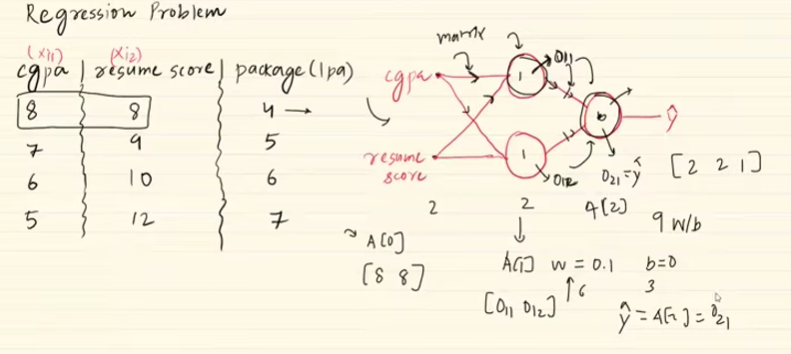

In [ ]:
# Step 0: Parameter initialization
parameters = initialize_parameters([2,2,1])

# Step 1: Select a student 
X = df[['cgpa', 'profile_score']].values[0].reshape(2,1) # Shape(no of features, no. of training example)
y = df[['lpa']].values[0][0]

# Step 2: Forward Propagation (calculating the output of the model)
y_hat,A1 = L_layer_forward(X, parameters) # A1 is the output of the first layer (O11 and O12) and y_hat is the output of the second layer

A0:  [[8]
 [8]]
W1:  [[0.1 0.1]
 [0.1 0.1]]
b1:  [[0.]
 [0.]]
----------------------------------------
A1:  [[1.6]
 [1.6]]
****************************************
A1:  [[1.6]
 [1.6]]
W2:  [[0.1]
 [0.1]]
b2:  [[0.]]
----------------------------------------
A2:  [[0.32]]
****************************************


In [13]:
print("Output of the model:", y_hat)
print("Output of the first layer as it is used in partial derivatives:", A1)

Output of the model: 0.32000000000000006
Output of the first layer as it is used in partial derivatives: [[1.6]
 [1.6]]


In [14]:
# Step 3: Calculating the loss (cost function)
cost = (y - y_hat)**2
print("Cost for the selected student: ", cost)

Cost for the selected student:  13.542399999999997


In [16]:
# Step 4: Backpropagation (calculating the gradients and updating the weights and biases)
update_parameters(parameters,y,y_hat,A1,X)

In [17]:
parameters

{'W1': array([[0.10658137, 0.10658137],
        [0.10658137, 0.10658137]]),
 'b1': array([[0.00082267],
        [0.00082267]]),
 'W2': array([[0.111776],
        [0.111776]]),
 'b2': array([[0.119136]])}

- Repeating the same process for another student

In [21]:
X = df[['cgpa', 'profile_score']].values[1].reshape(2,1) # Shape(no of features, no. of training exaplme)
y = df[['lpa']].values[1][0]

y_hat,A1 = L_layer_forward(X,parameters)
y_hat = y_hat[0][0]

update_parameters(parameters,y,y_hat,A1,X)

parameters

A0:  [[7]
 [9]]
W1:  [[0.11533984 0.1276017 ]
 [0.11533984 0.1276017 ]]
b1:  [[0.00257437]
 [0.00257437]]
----------------------------------------
A1:  [[1.84801186]
 [2.04420165]]
****************************************
A1:  [[1.84801186]
 [2.04420165]]
W2:  [[0.13525283]
 [0.13525283]]
b2:  [[0.14820409]]
----------------------------------------
A2:  [[0.67463696]]
****************************************


{'W1': array([[0.12449816, 0.13937669],
        [0.12460094, 0.13950882]]),
 'b1': array([[0.0038827 ],
        [0.00389738]]),
 'W2': array([[0.15123947],
        [0.15293665]]),
 'b2': array([[0.16158738]])}

- Repeating the same process for another student

In [23]:
X = df[['cgpa', 'profile_score']].values[2].reshape(2,1) # Shape(no of features, no. of training exaplme)
y = df[['lpa']].values[2][0]

y_hat,A1 = L_layer_forward(X,parameters)
y_hat = y_hat[0][0]

update_parameters(parameters,y,y_hat,A1,X)

parameters

A0:  [[ 6]
 [10]]
W1:  [[0.13541309 0.16557251]
 [0.13581219 0.16641584]]
b1:  [[0.00606568]
 [0.00613963]]
----------------------------------------
A1:  [[2.17666613]
 [2.66373308]]
****************************************
A1:  [[2.17666613]
 [2.66373308]]
W2:  [[0.17735337]
 [0.18216837]]
b2:  [[0.19447704]]
----------------------------------------
A2:  [[1.06576402]]
****************************************


{'W1': array([[0.1471862 , 0.18519436],
        [0.14815501, 0.1869872 ]]),
 'b1': array([[0.00802787],
        [0.00819677]]),
 'W2': array([[0.19883374],
        [0.20845534]]),
 'b2': array([[0.21832381]])}

- Repeating the same process for another student

In [22]:
#------------------ Repeating the same process for another student-------------------------------------

X = df[['cgpa', 'profile_score']].values[3].reshape(2,1) # Shape(no of features, no. of training example)
y = df[['lpa']].values[3][0]

y_hat,A1 = L_layer_forward(X, parameters)

update_parameters(parameters,y,y_hat,A1,X)

A0:  [[ 5]
 [12]]
W1:  [[0.12449816 0.13937669]
 [0.12460094 0.13950882]]
b1:  [[0.0038827 ]
 [0.00389738]]
----------------------------------------
A1:  [[2.12158473]
 [2.37488668]]
****************************************
A1:  [[2.12158473]
 [2.37488668]]
W2:  [[0.15123947]
 [0.15293665]]
b2:  [[0.16158738]]
----------------------------------------
A2:  [[0.84566196]]
****************************************


C:\Users\Kaushik Mandal\AppData\Local\Temp\ipykernel_15404\332058445.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  parameters['W2'][0][0] = parameters['W2'][0][0] + (0.001 * 2 * (y - y_hat)*A1[0][0])
C:\Users\Kaushik Mandal\AppData\Local\Temp\ipykernel_15404\332058445.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  parameters['W2'][1][0] = parameters['W2'][1][0] + (0.001 * 2 * (y - y_hat)*A1[1][0])
C:\Users\Kaushik Mandal\AppData\Local\Temp\ipykernel_15404\332058445.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your arr

- ### Implementation of the above logic using epochs

In [25]:
# epochs implementation

parameters = initialize_parameters([2,2,1])
epochs = 5

Average_Loss = []

for i in range(epochs):

  Loss = []

  for j in range(df.shape[0]):

    X = df[['cgpa', 'profile_score']].values[j].reshape(2,1) # Shape(no of features, no. of training example)
    y = df[['lpa']].values[j][0]

    # Parameter initialization


    y_hat,A1 = L_layer_forward(X,parameters)
    y_hat = y_hat[0][0]

    update_parameters(parameters,y,y_hat,A1,X)

    Loss.append((y-y_hat)**2) 

  Average_Loss.append(np.array(Loss).mean())
  print('Epoch - ',i+1,'Loss - ',Average_Loss[-1])


A0:  [[8]
 [8]]
W1:  [[0.1 0.1]
 [0.1 0.1]]
b1:  [[0.]
 [0.]]
----------------------------------------
A1:  [[1.6]
 [1.6]]
****************************************
A1:  [[1.6]
 [1.6]]
W2:  [[0.1]
 [0.1]]
b2:  [[0.]]
----------------------------------------
A2:  [[0.32]]
****************************************
A0:  [[7]
 [9]]
W1:  [[0.10658137 0.10658137]
 [0.10658137 0.10658137]]
b1:  [[0.00082267]
 [0.00082267]]
----------------------------------------
A1:  [[1.70612461]
 [1.70612461]]
****************************************
A1:  [[1.70612461]
 [1.70612461]]
W2:  [[0.111776]
 [0.111776]]
b2:  [[0.119136]]
----------------------------------------
A2:  [[0.50054357]]
****************************************
A0:  [[ 6]
 [10]]
W1:  [[0.11458955 0.1168776 ]
 [0.11458955 0.1168776 ]]
b1:  [[0.0019667]
 [0.0019667]]
----------------------------------------
A1:  [[1.83539945]
 [1.87200826]]
****************************************
A1:  [[1.83539945]
 [1.87200826]]
W2:  [[0.12712927]
 [0.127

In [26]:
# Printing average loss for each epoch

for i in range(len(Average_Loss)):
  print('Epoch - ',i+1,'Loss - ',Average_Loss[i])

Epoch -  1 Loss -  25.321744156025517
Epoch -  2 Loss -  18.320004165722047
Epoch -  3 Loss -  9.473661050729628
Epoch -  4 Loss -  3.2520938634031613
Epoch -  5 Loss -  1.3407132589299962


# Let's implement the same code using keras and see the difference in the code

In [27]:
df = pd.DataFrame([[8,8,4],[7,9,5],[6,10,6],[5,12,7]], columns=['cgpa', 'profile_score', 'lpa'])

In [28]:
df

,cgpa,profile_score,lpa
0,8,8,4
1,7,9,5
2,6,10,6
3,5,12,7


In [29]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

In [30]:
model = Sequential()
model.add(Dense(2, input_dim=2, activation='linear'))
model.add(Dense(1, activation='linear'))

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.get_weights()

[array([[ 0.11179674,  0.8632833 ],
        [-0.82708997,  0.6681472 ]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.8297571 ],
        [0.04843688]], dtype=float32),
 array([0.], dtype=float32)]

- Keras by default does random weight initialization, so we will not get the same results as above, so we will set the keras weight initialization to be the same as ours

In [38]:
# making a new weights all initialized to 0.1 and biases to 0

new_weights = [
    (np.ones((2, 2)) * 0.1).astype(np.float32),
    np.zeros((2,)).astype(np.float32),
    (np.ones((2, 1)) * 0.1).astype(np.float32),
    np.zeros((1,)).astype(np.float32)
]

In [39]:
model.set_weights(new_weights)

In [40]:
model.get_weights()

[array([[0.1, 0.1],
        [0.1, 0.1]], dtype=float32),
 array([0., 0.], dtype=float32),
 array([[0.1],
        [0.1]], dtype=float32),
 array([0.], dtype=float32)]

In [41]:
# Setting learning rate to 0.001 as we did in our implementation above

optimizer = keras.optimizers.Adam(learning_rate=0.001)

In [44]:
model.compile(optimizer=optimizer, loss='mean_squared_error')

In [46]:
history = model.fit(df.iloc[:, :-1].values,df['lpa'], epochs=75, batch_size=1, verbose=0)

In [47]:
history.history['loss']

[1.4302997589111328,
 1.4014317989349365,
 1.3466408252716064,
 1.3255891799926758,
 1.278835654258728,
 1.2456469535827637,
 1.2483887672424316,
 1.1968332529067993,
 1.1933764219284058,
 1.1810203790664673,
 1.1408485174179077,
 1.1352542638778687,
 1.1144914627075195,
 1.1040831804275513,
 1.1052533388137817,
 1.093993067741394,
 1.081809639930725,
 1.069129467010498,
 1.0631078481674194,
 1.0609302520751953,
 1.0523624420166016,
 1.0485903024673462,
 1.0439671277999878,
 1.0452195405960083,
 1.0367964506149292,
 1.0361340045928955,
 1.0298116207122803,
 1.0267831087112427,
 1.025126338005066,
 1.023862600326538,
 1.021321177482605,
 1.0174592733383179,
 1.0149041414260864,
 1.013380527496338,
 1.015122890472412,
 1.0087918043136597,
 1.0083101987838745,
 1.008893370628357,
 1.0051062107086182,
 1.0007745027542114,
 1.0022504329681396,
 1.001949667930603,
 0.9986511468887329,
 0.9943872094154358,
 0.9931327700614929,
 0.9910098910331726,
 0.9927420020103455,
 0.990094780921936,
 0.9

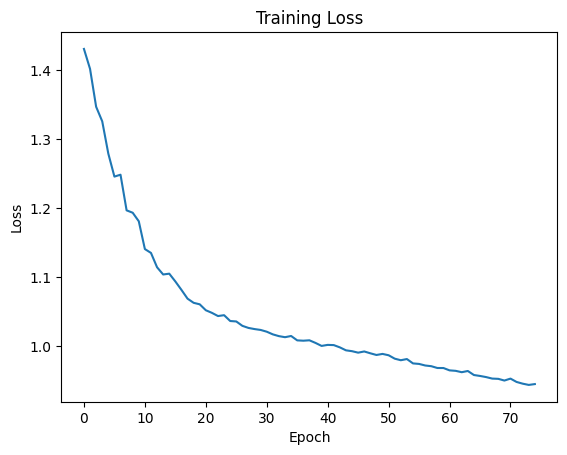

In [49]:
# Loss vs Epochs

import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.show()